# Fraudadores realistas no SynCCFD

Este notebook mostra as fraudes **injetadas** do SynCCFD (Fase 3 do plano
`docs/plan-v0.2.md`): o fraudador faz transações **novas**, que se somam às do
cliente; as transações legítimas nunca são alteradas nem rotuladas como fraude.

| # | cenário | o que o fraudador faz |
|---|---|---|
| 1 | valor anômalo | uma compra muito acima do histórico recente do cliente: $2 \times$ o quantil 95% das compras dos últimos 30 dias, vezes $1 + 0{,}5\,U$ |
| 2 | terminal comprometido | um terminal comprometido por 28 dias lê o cartão de quem compra ali (a compra continua legítima); de 1 a 14 dias depois, 20% dos cartões lidos são clonados (compras CP em sequência perto do fraudador) e 5% vão para o cenário 3 |
| 3 | número do cartão roubado | rajadas de 2 a 5 compras CNP em até 3 h, entregues no endereço do fraudador, com viés noturno e valores em torno de $2 \times$ a mediana recente do cliente |
| 4 | cartão físico roubado | compras em sequência (a cada 20 min, em média) perto da cidade da vítima, até o bloqueio, o limite de gasto ou 24 h |
| 5 | *card testing* | de 3 a 10 compras CNP de R\$ 1 a 5 em poucos minutos; em metade dos casos, o fraudador segue para o cenário 3 com o mesmo cartão |

`FraudConfig.realistic()` liga os cinco cenários, com taxas proporcionais à população
e *drift* dos fraudadores: o cenário 2 cai pela metade a partir de 60% do período
(chip) e o cenário 5 surge a partir de 30%. As figuras são gravadas em PDF em
`docs/figures/fase3/`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from synccfd import DatasetGenerator
from synccfd.simulator import presets
from synccfd.simulator.config import MerchantConfig
from synccfd.simulator.engine.drift import CustomerDrift, regime_weight
from synccfd.simulator.ground_truth import compromise_table

# Where the figures are saved (the tests point this to a temporary folder)
FIG_DIR = Path(os.environ.get("SYNCCFD_FIG_DIR", "../docs/figures/fase3"))
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Validated categorical palette, in fixed order (one color per scenario)
SCENARIO_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", 4: "#eda100", 5: "#e87ba4"}
SCENARIO_NAMES = {
    1: "1 · valor anômalo",
    2: "2 · terminal comprometido",
    3: "3 · número do cartão roubado",
    4: "4 · cartão físico roubado",
    5: "5 · card testing",
}
MUTED, INK, SECONDARY = "#8a8985", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "font.size": 10,
})

## Geração

O conjunto de dados é o da configuração final da dissertação ("Fechamento do [SIM]" em
`docs/plan-v0.2.md`): `presets.realistic()`, com `FraudConfig.realistic()`, *drift* de
clientes (30%), sazonalidade e comerciantes.

In [2]:
# The final configuration; scripts/make_figures.py and the tests set SYNCCFD_*
PARAMS = presets.from_env()
fraud = PARAMS["fraud"]
assert fraud is not None and 5 in fraud.scenarios, "this notebook needs the five fraud scenarios"
N_CUSTOMERS, N_TERMINALS, NB_DAYS, SEED = (
    PARAMS[k] for k in ("n_customers", "n_terminals", "nb_days", "random_state")
)
customers, terminals, transactions = DatasetGenerator(**PARAMS).generate()
frauds = transactions[transactions.TX_FRAUD == 1]
print(f"{len(transactions):,} transações; taxa de fraude {transactions.TX_FRAUD.mean():.3%}")
summary = frauds.groupby("TX_FRAUD_SCENARIO").agg(
    transacoes=("TRANSACTION_ID", "size"), campanhas=("GT_CAMPAIGN_ID", "nunique"),
    valor_mediano=("TX_AMOUNT", "median"),
)
summary["taxa_%"] = 100 * summary.transacoes / len(transactions)
summary.rename(index=SCENARIO_NAMES).round(3)

3,735,430 transações; taxa de fraude 0.356%


,transacoes,campanhas,valor_mediano,taxa_%
TX_FRAUD_SCENARIO,,,,
1 · valor anômalo,527,527,1602.03,0.014
2 · terminal comprometido,1165,235,121.87,0.031
3 · número do cartão roubado,7274,720,272.94,0.195
4 · cartão físico roubado,2623,547,116.08,0.070
5 · card testing,1694,256,3.03,0.045


## Taxa por cenário ao longo do tempo

Fração semanal das transações que são fraude de cada cenário. As linhas verticais
marcam o *drift* dos fraudadores: a queda do cenário 2 (60% do período) e o início do
cenário 5 (30%).

Mesmo com 10 000 clientes, cada cenário tem poucos ataques por dia (cerca de 1 terminal
comprometido por dia, por exemplo), e o número de compras por terminal é muito
desigual. Num único conjunto, a curva semanal oscila muito e pode sugerir tendências
que não existem. Por isso a figura mostra a média de 10 seeds (linha) e a faixa entre a
menor e a maior seed.

In [3]:
SEEDS = range(SEED, SEED + 10)
n_weeks = NB_DAYS // 7  # the last, partial week is left out


def weekly_rates(data):
    # % of each week's transactions that are fraud of each scenario
    week = data.TX_TIME_DAYS // 7
    keep = week < n_weeks
    counts = pd.crosstab(week[keep], data.TX_FRAUD_SCENARIO[keep])
    return 100 * counts.div(counts.sum(axis=1), axis=0).reindex(columns=range(6), fill_value=0)


rates = [weekly_rates(transactions)]
for seed in SEEDS[1:]:
    _, _, other = DatasetGenerator(**{**PARAMS, "random_state": seed}).generate()
    rates.append(weekly_rates(other))
    del other

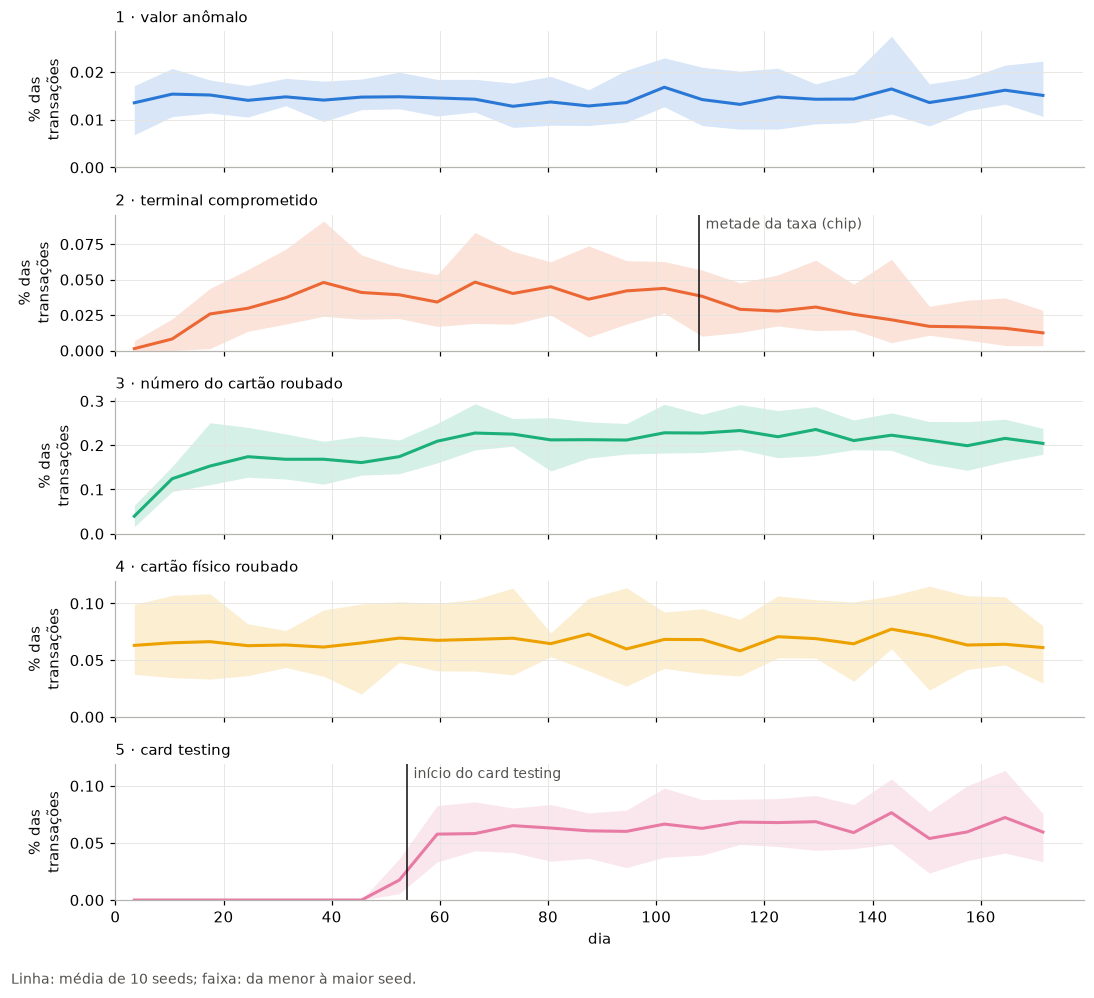

In [4]:
changes = {2: 0.6 * NB_DAYS, 5: 0.3 * NB_DAYS}
days = np.arange(n_weeks) * 7 + 3.5

fig, axes = plt.subplots(5, 1, figsize=(10, 9), sharex=True)
for ax, scenario in zip(axes, SCENARIO_NAMES):
    per_seed = np.vstack([r[scenario].to_numpy() for r in rates])
    color = SCENARIO_COLORS[scenario]
    ax.fill_between(days, per_seed.min(axis=0), per_seed.max(axis=0), color=color, alpha=0.18, lw=0)
    ax.plot(days, per_seed.mean(axis=0), color=color, lw=2)
    if scenario in changes:
        ax.axvline(changes[scenario], color=INK, lw=1)
        ax.annotate(
            "metade da taxa (chip)" if scenario == 2 else "início do card testing",
            (changes[scenario], 1), xycoords=("data", "axes fraction"),
            xytext=(4, -2), textcoords="offset points", va="top", fontsize=9, color=SECONDARY,
        )
    ax.set_ylim(bottom=0)
    ax.set_title(SCENARIO_NAMES[scenario], loc="left", fontsize=10)
    ax.set_ylabel("% das\ntransações")
axes[-1].set_xlabel("dia")
axes[-1].set_xlim(0, NB_DAYS - 1)
fig.text(0.01, 0.0, f"Linha: média de {len(rates)} seeds; faixa: da menor à maior seed.",
         fontsize=9, color=SECONDARY)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(FIG_DIR / "fraudes_taxa_por_cenario.pdf", bbox_inches="tight")
plt.show()

## Uma campanha: *card testing* → número do cartão roubado

Uma campanha em que o fraudador testa o cartão (cenário 5) e depois o usa em compras
CNP (cenário 3), com o mesmo `GT_CAMPAIGN_ID`. Em cinza, as compras legítimas da
vítima no mesmo período, que continuam normalmente.

In [5]:
by_campaign = frauds.groupby("GT_CAMPAIGN_ID")
scenarios_in = by_campaign.TX_FRAUD_SCENARIO.agg(set)
escalated = scenarios_in[scenarios_in.apply(lambda s: s == {3, 5})].index
bursts = frauds[frauds.GT_CAMPAIGN_ID.isin(escalated) & (frauds.TX_FRAUD_SCENARIO == 3)]
# A campaign with several bursts, in the middle of the period
n_days_used = bursts.groupby("GT_CAMPAIGN_ID").TX_TIME_DAYS.nunique()
start = by_campaign.TX_TIME_SECONDS.min()
candidates = n_days_used[(n_days_used >= 3)].index
candidates = [c for c in candidates if 0.4 * NB_DAYS < start[c] / 86400 < 0.8 * NB_DAYS]
campaign_id = candidates[0]
campaign = frauds[frauds.GT_CAMPAIGN_ID == campaign_id]
victim = campaign.CUSTOMER_ID.iloc[0]
t_first = campaign.TX_TIME_SECONDS.min()
t_last = campaign.TX_TIME_SECONDS.max()
own = transactions[(transactions.CUSTOMER_ID == victim) & (transactions.TX_FRAUD == 0)]
own = own[own.TX_TIME_SECONDS.between(t_first - 3 * 86400, t_last + 3 * 86400)]
campaign[["TX_DATETIME", "TX_FRAUD_SCENARIO", "TX_AMOUNT", "TX_TYPE", "GT_FRAUDSTER_ID"]]

,TX_DATETIME,TX_FRAUD_SCENARIO,TX_AMOUNT,TX_TYPE,GT_FRAUDSTER_ID
1482741,2023-03-14 13:04:35,5,3.82,CNP,220
1482753,2023-03-14 13:05:13,5,1.40,CNP,220
1482759,2023-03-14 13:05:28,5,2.42,CNP,220
1482761,2023-03-14 13:05:35,5,3.21,CNP,220
1482765,2023-03-14 13:05:44,5,3.98,CNP,220
1482808,2023-03-14 13:08:40,5,4.19,CNP,220
1482825,2023-03-14 13:09:51,5,4.90,CNP,220
1482828,2023-03-14 13:10:08,5,2.33,CNP,220
1515698,2023-03-15 23:55:41,3,297.97,CNP,220
1515964,2023-03-16 00:44:02,3,385.76,CNP,220


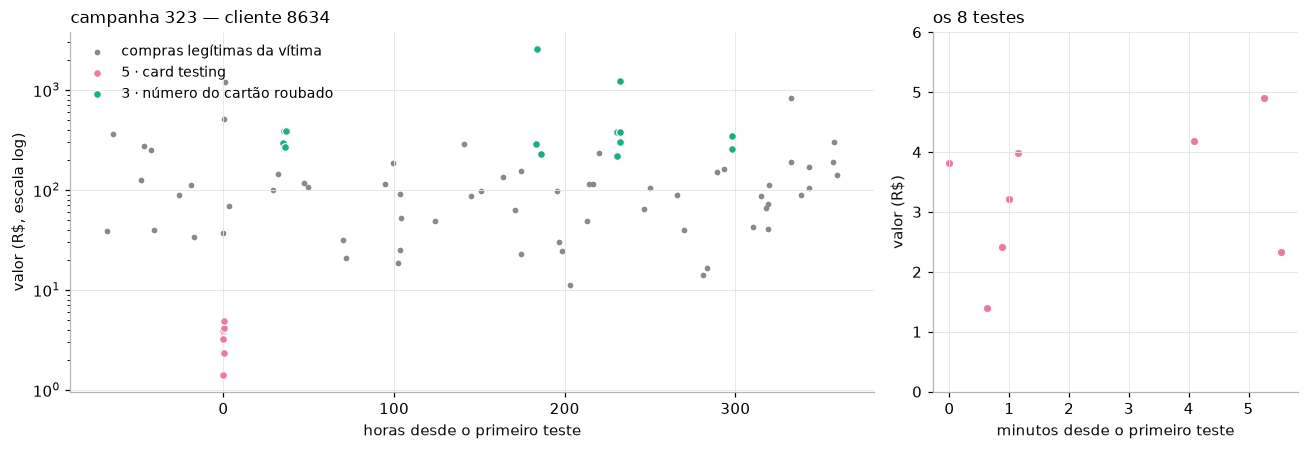

In [6]:
fig, (ax_all, ax_tests) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})

hours = lambda s: (s - t_first) / 3600  # noqa: E731
ax_all.scatter(hours(own.TX_TIME_SECONDS), own.TX_AMOUNT, s=14, color=MUTED, lw=0,
               label="compras legítimas da vítima")
for scenario in (5, 3):
    part = campaign[campaign.TX_FRAUD_SCENARIO == scenario]
    ax_all.scatter(hours(part.TX_TIME_SECONDS), part.TX_AMOUNT, s=26, color=SCENARIO_COLORS[scenario],
                   edgecolor="#fcfcfb", lw=0.8, label=SCENARIO_NAMES[scenario], zorder=3)
ax_all.set_yscale("log")
ax_all.set_xlabel("horas desde o primeiro teste")
ax_all.set_ylabel("valor (R$, escala log)")
ax_all.set_title(f"campanha {campaign_id} — cliente {victim}", loc="left", fontsize=11)
ax_all.legend(loc="upper left", frameon=False, fontsize=9)

tests = campaign[campaign.TX_FRAUD_SCENARIO == 5]
minutes = (tests.TX_TIME_SECONDS - t_first) / 60
ax_tests.scatter(minutes, tests.TX_AMOUNT, s=30, color=SCENARIO_COLORS[5], edgecolor="#fcfcfb", lw=0.8)
ax_tests.set_ylim(0, 6)
ax_tests.set_xlabel("minutos desde o primeiro teste")
ax_tests.set_ylabel("valor (R$)")
ax_tests.set_title(f"os {len(tests)} testes", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "fraudes_campanha_card_testing.pdf", bbox_inches="tight")
plt.show()

## Pontos de comprometimento (cenário 2)

O terminal comprometido não gera fraude: ele lê o cartão de quem compra ali, e a compra
continua legítima. O gabarito marca essa compra com `GT_COMPROMISE_ID`, e as fraudes
feitas depois com o mesmo cartão (clonado, no cenário 2, ou só o número, no cenário 3)
levam o mesmo id. `compromise_table` monta a tabela de comprometimentos.

In [7]:
compromises = compromise_table(transactions)
use = compromises.USE_SCENARIO.map({2: "clonado (cenário 2)", 3: "número vazado (cenário 3)"})
print(f"{len(compromises):,} cartões lidos em {compromises.TERMINAL_ID.nunique()} terminais comprometidos")
display(use.fillna("não usado").value_counts().to_frame("cartões"))
compromises.dropna(subset=["USE_SCENARIO"]).head()

1,236 cartões lidos em 239 terminais comprometidos


,cartões
USE_SCENARIO,
não usado,948
clonado (cenário 2),235
número vazado (cenário 3),53


,GT_COMPROMISE_ID,CUSTOMER_ID,TERMINAL_ID,READ_TRANSACTION_ID,READ_DATETIME,GT_FRAUDSTER_ID,USE_SCENARIO,N_FRAUD_TX,FIRST_FRAUD_DATETIME
13,84,5378,8374,96274,2023-01-05 20:29:43,6,2,3,2023-01-15 10:58:27
18,64,2324,15884,115662,2023-01-06 18:38:46,5,2,5,2023-01-17 14:09:57
21,44,4836,177,120700,2023-01-06 21:51:03,4,2,1,2023-01-12 18:24:47
25,77,8409,15884,130383,2023-01-07 13:21:35,5,2,7,2023-01-15 09:50:59
26,5,949,8310,136437,2023-01-07 17:32:16,1,2,7,2023-01-18 14:55:29


## Valor por cenário

Distribuição dos valores das transações legítimas e das fraudes de cada cenário
(escala log). As fraudes dos cenários 1 a 4 ficam acima do padrão do cliente (as do
cenário 2 são compras com o cartão clonado, como no cenário 4); as do cenário 5 são de
R\$ 1 a 5.

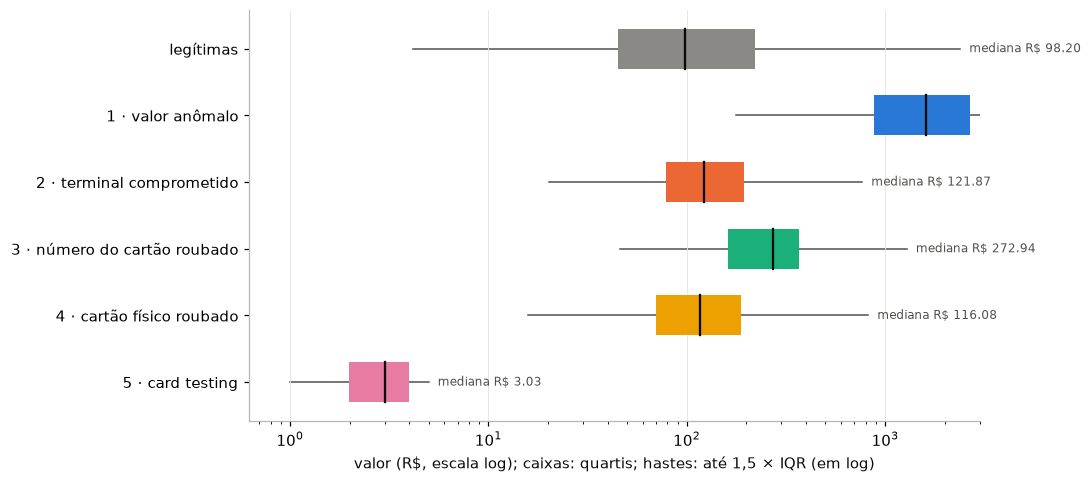

In [8]:
groups = [("legítimas", transactions.loc[transactions.TX_FRAUD == 0, "TX_AMOUNT"], MUTED)]
groups += [(SCENARIO_NAMES[s], frauds.loc[frauds.TX_FRAUD_SCENARIO == s, "TX_AMOUNT"], SCENARIO_COLORS[s])
           for s in SCENARIO_NAMES]
groups = groups[::-1]  # legitimate on top

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, (_, values, color) in enumerate(groups):
    # Box plot on the log scale: quartiles and whiskers computed on log10(amount)
    logs = np.log10(values[values > 0])
    q1, median, q3 = np.quantile(logs, [0.25, 0.5, 0.75])
    low = logs[logs >= q1 - 1.5 * (q3 - q1)].min()
    high = logs[logs <= q3 + 1.5 * (q3 - q1)].max()
    ax.plot([10**low, 10**high], [i, i], color=SECONDARY, lw=1, zorder=1)
    ax.barh(i, 10**q3 - 10**q1, left=10**q1, height=0.6, color=color, zorder=2)
    ax.plot([10**median] * 2, [i - 0.3, i + 0.3], color=INK, lw=1.5, zorder=3)
    ax.annotate(f"mediana R$ {10**median:,.2f}", (10**high, i), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=SECONDARY)
ax.set_yticks(range(len(groups)), [g[0] for g in groups])
ax.set_xscale("log")
ax.set_xlim(right=3e3)
ax.set_xlabel("valor (R$, escala log); caixas: quartis; hastes: até 1,5 × IQR (em log)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fraudes_valor_por_cenario.pdf", bbox_inches="tight")
plt.show()

## Cenário 1 e *drift*: regra de rótulo por limiar fixo × fraude injetada

Uma regra de rótulo por limiar fixo (toda transação acima de R\$ 220 é fraude, como
no simulador do artigo) rotula compras legítimas, e com *drift* atinge
principalmente os clientes cujo regime B gasta mais. Aqui, nos mesmos dados,
aplicamos o limiar de R\$ 220 diretamente às transações legítimas e comparamos:

- a fração das transações legítimas que vêm do regime B;
- a regra de rótulo por limiar fixo: de que regime vêm as transações que ela
  rotularia;
- a fraude injetada do cenário 1: em que regime estava a vítima no dia da fraude
  (peso $w$ do regime B, pelo gabarito do cliente).

In [9]:
def victim_weight(row):
    # Weight of regime B for the victim of a fraud, on the day of the fraud
    profile = customers.loc[row.CUSTOMER_ID]
    def value(name):
        return 0 if pd.isna(profile[name]) else int(profile[name])
    drift = CustomerDrift(kind=profile.GT_DRIFT_TYPE, t0=value("GT_DRIFT_T0"),
                          transition_days=value("GT_DRIFT_L"), period_days=value("GT_DRIFT_PERIOD"),
                          active_days=value("GT_DRIFT_ACTIVE_DAYS"))
    return regime_weight(drift, np.array([row.TX_TIME_DAYS + 0.5]))[0]


legit = transactions[transactions.TX_FRAUD == 0]
s1 = frauds[frauds.TX_FRAUD_SCENARIO == 1]
over_threshold = legit[legit.TX_AMOUNT > 220]
check = pd.Series({
    "transações do cenário 1": len(s1),
    "das quais são transações legítimas (têm GT_REGIME)": int(s1.GT_REGIME.notna().sum()),
    "transações legítimas rotuladas como fraude, em qualquer cenário": int(
        (transactions.GT_REGIME.notna() & (transactions.TX_FRAUD == 1)).sum()
    ),
})
shares = pd.Series({
    "transações legítimas no regime B": (legit.GT_REGIME == "B").mean(),
    "regra de rótulo por limiar fixo (R$ 220): rotuladas do regime B": (
        over_threshold.GT_REGIME == "B"
    ).mean(),
    "fraude injetada (cenário 1): vítimas no regime B": s1.apply(victim_weight, axis=1).mean(),
})
display(check.to_frame("contagem"))
(100 * shares).round(1).to_frame("%")

,contagem
transações do cenário 1,527
das quais são transações legítimas (têm GT_REGIME),0
"transações legítimas rotuladas como fraude, em qualquer cenário",0


,%
transações legítimas no regime B,13.1
regra de rótulo por limiar fixo (R$ 220): rotuladas do regime B,13.9
fraude injetada (cenário 1): vítimas no regime B,12.2


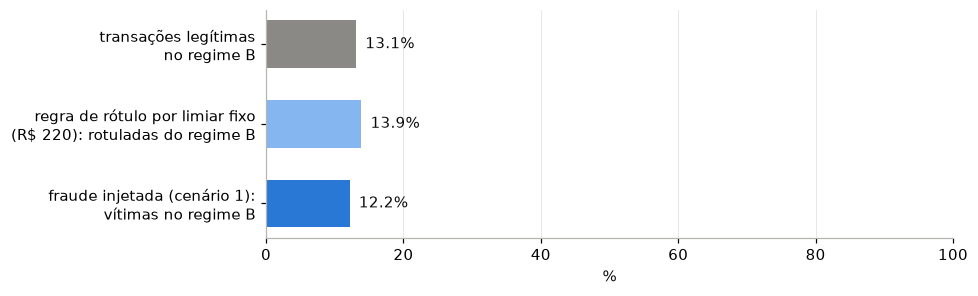

In [10]:
fig, ax = plt.subplots(figsize=(9, 2.8))
labels = ["transações legítimas\nno regime B",
          "regra de rótulo por limiar fixo\n(R$ 220): rotuladas do regime B",
          "fraude injetada (cenário 1):\nvítimas no regime B"]
# Scenario 1 in its color; the old rule in a lighter step of the same hue
colors = [MUTED, "#86b6ef", SCENARIO_COLORS[1]]
y = np.arange(len(shares))[::-1]
ax.barh(y, 100 * shares.to_numpy(), color=colors, height=0.6)
for yi, value in zip(y, 100 * shares.to_numpy()):
    ax.annotate(f"{value:.1f}%", (value, yi), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=10, color=INK)
ax.set_yticks(y, labels)
ax.set_xlim(0, 100)
ax.set_xlabel("%")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fraudes_cenario1_regime_b.pdf", bbox_inches="tight")
plt.show()

## Visão por categoria (com comerciantes)

Com comerciantes (`MerchantConfig`, Fase 4), cada cenário compra em categorias
próprias (a configuração final tem comerciantes; com um *preset* sem eles, o notebook
gera os mesmos dados com comerciantes):

- **cenário 1:** categorias de valor alto (eletrônicos, viagem);
- **cenário 2:** o comerciante inteiro é comprometido, escolhido pelo risco da categoria
  (posto 3, restaurante 2, demais 1), e o cartão clonado é usado em categorias
  revendáveis;
- **cenário 3:** categorias revendáveis ou digitais, com valores acima da mediana da
  categoria. Em `FraudConfig.realistic()`, ele migra de eletrônicos para serviços
  digitais a partir de 50% do período;
- **cenário 4:** categorias revendáveis (eletrônicos, posto, farmácia, supermercado),
  só com o comerciante aberto;
- **cenário 5:** serviços digitais.

taxa de fraude com comerciantes: 0.356%


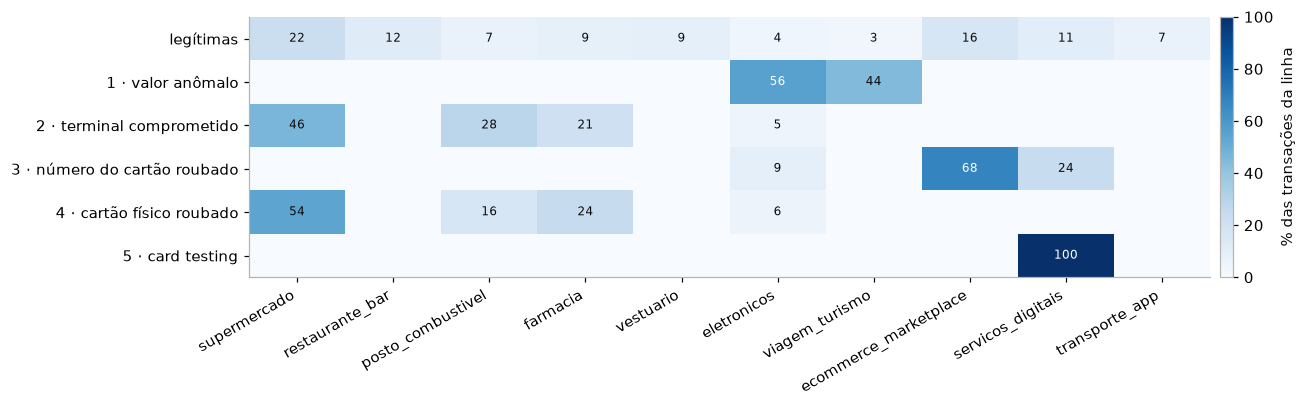

In [11]:
if PARAMS.get("merchants") is not None:
    shop_terminals, shop_tx = terminals, transactions
else:
    _, shop_terminals, shop_tx = DatasetGenerator(**{**PARAMS, "merchants": MerchantConfig()}).generate()
CATEGORY_NAMES = list((PARAMS.get("merchants") or MerchantConfig()).names)
group = shop_tx.TX_FRAUD_SCENARIO.map(lambda s: "legítimas" if s == 0 else SCENARIO_NAMES[s])
table = pd.crosstab(group, shop_tx.MERCHANT_CATEGORY, normalize="index").reindex(
    index=["legítimas", *SCENARIO_NAMES.values()], columns=CATEGORY_NAMES, fill_value=0
)
print(f"taxa de fraude com comerciantes: {shop_tx.TX_FRAUD.mean():.3%}")

fig, ax = plt.subplots(figsize=(12, 3.8))
image = ax.imshow(100 * table.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=100)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        value = 100 * table.iat[i, j]
        if value >= 1:
            ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8,
                    color="#ffffff" if value > 55 else INK)
ax.set_xticks(range(len(CATEGORY_NAMES)), CATEGORY_NAMES, rotation=30, ha="right")
ax.set_yticks(range(len(table)), table.index)
ax.grid(False)
colorbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.01)
colorbar.set_label("% das transações da linha")
fig.tight_layout()
fig.savefig(FIG_DIR / "fraudes_categoria_por_cenario.pdf", bbox_inches="tight")
plt.show()

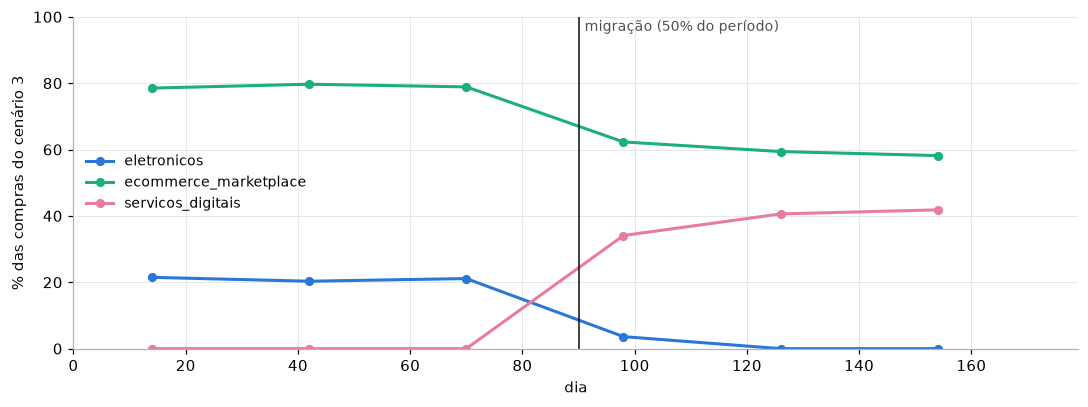

In [12]:
# Scenario 3 over time: share of its purchases in each category, per 4 weeks (the
# last, partial block is left out)
s3 = shop_tx[(shop_tx.TX_FRAUD_SCENARIO == 3) & (shop_tx.TX_TIME_DAYS < NB_DAYS // 28 * 28)]
block = s3.TX_TIME_DAYS // 28
s3_shares = pd.crosstab(block, s3.MERCHANT_CATEGORY, normalize="index")
s3_colors = {"eletronicos": SCENARIO_COLORS[1], "ecommerce_marketplace": SCENARIO_COLORS[3],
             "servicos_digitais": SCENARIO_COLORS[5]}
fig, ax = plt.subplots(figsize=(10, 3.8))
x = s3_shares.index * 28 + 14
for name, color in s3_colors.items():
    values = 100 * s3_shares.get(name, pd.Series(0.0, index=s3_shares.index))
    ax.plot(x, values, color=color, lw=2, marker="o", markersize=5, label=name)
ax.axvline(0.5 * NB_DAYS, color=INK, lw=1)
ax.annotate("migração (50% do período)", (0.5 * NB_DAYS, 1), xycoords=("data", "axes fraction"),
            xytext=(4, -2), textcoords="offset points", va="top", fontsize=9, color=SECONDARY)
ax.set_xlim(0, NB_DAYS - 1)
ax.set_ylim(0, 100)
ax.set_xlabel("dia")
ax.set_ylabel("% das compras do cenário 3")
ax.legend(loc="center left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fraudes_cenario3_migracao.pdf", bbox_inches="tight")
plt.show()